In [1]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
print("✅ Library berhasil di-import!")

✅ Library berhasil di-import!


In [2]:
# Membaca dataset
df = pd.read_csv('Well_Dataset.csv')
print(f"Dimensi Data: {df.shape[0]:,} baris × {df.shape[1]} kolom")

Dimensi Data: 2,060 baris × 14 kolom


In [24]:
# Melihat 5 baris pertama
df.head()

,Formation,TMD (m),TVD (m),ROP (m/hr),WOB (ton),FR (gpm),SPP (psi),RPM (rpm),TQ (lb.ft),MW IN (ppg),MW OUT (ppg),RETURN (%),BIT TIME (hr),DATE TIME,MW_DIFF,DEPTH_CAT,FORMATION_CODE
0,Seno,428,428.01,33.3,3,514.3,818,70.0,1915.0,10.4,10.401,44,0.01,2010-06-19 07:12:15,0.001,Shallow,8
1,Seno,429,429.01,39.3,4,428.8,554,79.0,2383.0,10.4,10.403,40,0.05,2010-06-19 07:14:23,0.003,Shallow,8
2,Seno,430,430.00,26.7,3,442.7,547,79.0,2499.0,10.4,10.405,40,0.09,2010-06-19 07:16:43,0.005,Shallow,8
3,Seno,431,430.99,29.1,5,604.9,1259,82.0,1080.0,10.4,10.407,48,0.20,2010-06-19 09:04:13,0.007,Shallow,8
4,Seno,432,432.00,40.8,10,782.1,1846,92.0,3106.0,10.4,10.409,58,0.23,2010-06-19 09:05:52,0.009,Shallow,8


In [4]:
# Melihat formasi unik
print("🏷️ Formasi yang Ditembus:")
for f in df['Formation'].unique():
    print(f"  • {f}: {len(df[df['Formation']==f]):,} pts")

🏷️ Formasi yang Ditembus:
  • Seno: 342 pts
  • Turo: 89 pts
  • Ceno: 203 pts
  • Albi: 213 pts
  • Apti: 36 pts
  • Barre: 411 pts
  • Neo: 265 pts
  • Malcolm: 205 pts
  • Eren Shale: 252 pts
  • Mikasa Anhydrite: 44 pts


In [5]:
# Identifikasi missing values
missing = df.isnull().sum()
print("❓ Missing Values:")
for col in df.columns:
    if missing[col] > 0:
        print(f"  ⚠️ {col}: {missing[col]}")

❓ Missing Values:
  ⚠️ RPM (rpm): 1
  ⚠️ TQ (lb.ft): 1


In [6]:
#Interpolasi linear untuk mengisi missing values
df['RPM (rpm)'] = df['RPM (rpm)'].interpolate(method='linear')
df['TQ (lb.ft)'] = df['TQ (lb.ft)'].interpolate(method='linear')

print("✅ Missing values setelah interpolasi: 0")

✅ Missing values setelah interpolasi: 0


In [7]:
# Menghitung dan menghapus duplikat
duplicates = df.duplicated().sum()
print(f"🔍 Jumlah baris duplikat: {duplicates}")

df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"📊 Jumlah baris setelah cleaning: {len(df):,}")

🔍 Jumlah baris duplikat: 2
📊 Jumlah baris setelah cleaning: 2,058


In [8]:
# Konversi datetime
df['DATE TIME'] = pd.to_datetime(df['DATE TIME'], format='%d/%m/%Y %H.%M.%S')

print("📅 Rentang Waktu:")
print(f"   Mulai  : {df['DATE TIME'].min()}")
print(f"   Selesai: {df['DATE TIME'].max()}")

📅 Rentang Waktu:
   Mulai  : 2010-06-19 07:12:15
   Selesai: 2010-06-23 01:37:16


In [9]:
# Feature Engineering
df['MW_DIFF'] = df['MW OUT (ppg)'] - df['MW IN (ppg)']

df['DEPTH_CAT'] = pd.cut(df['TVD (m)'],
    bins=[0, 1000, 1500, 2000, 3000],
    labels=['Shallow', 'Medium', 'Deep', 'Very Deep'])

df['FORMATION_CODE'] = df['Formation'].astype('category').cat.codes

print("✅ Feature baru: MW_DIFF, DEPTH_CAT, FORMATION_CODE")

✅ Feature baru: MW_DIFF, DEPTH_CAT, FORMATION_CODE


In [10]:
# Statistik deskriptif
df[['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)']].describe().round(2)

,ROP (m/hr),WOB (ton),RPM (rpm),TQ (lb.ft)
count,2058.00,2058.00,2058.00,2058.00
mean,72.52,8.74,156.35,9213.45
std,32.64,3.59,23.84,3168.78
min,3.10,0.00,70.00,784.00
25%,49.72,7.00,146.00,6946.50
50%,67.20,9.00,158.00,9147.50
75%,91.88,11.00,167.00,11404.50
max,203.20,22.00,199.00,19822.00


In [11]:
# Rata-rata ROP per formasi
rop_by_formation = df.groupby('Formation')['ROP (m/hr)'].mean().sort_values(ascending=False)
print(rop_by_formation.round(2))

Formation
Albi                107.95
Neo                  88.50
Ceno                 87.61
Barre                77.36
Turo                 71.85
Seno                 62.29
Malcolm              52.14
Eren Shale           48.73
Apti                 47.53
Mikasa Anhydrite     22.12
Name: ROP (m/hr), dtype: float64


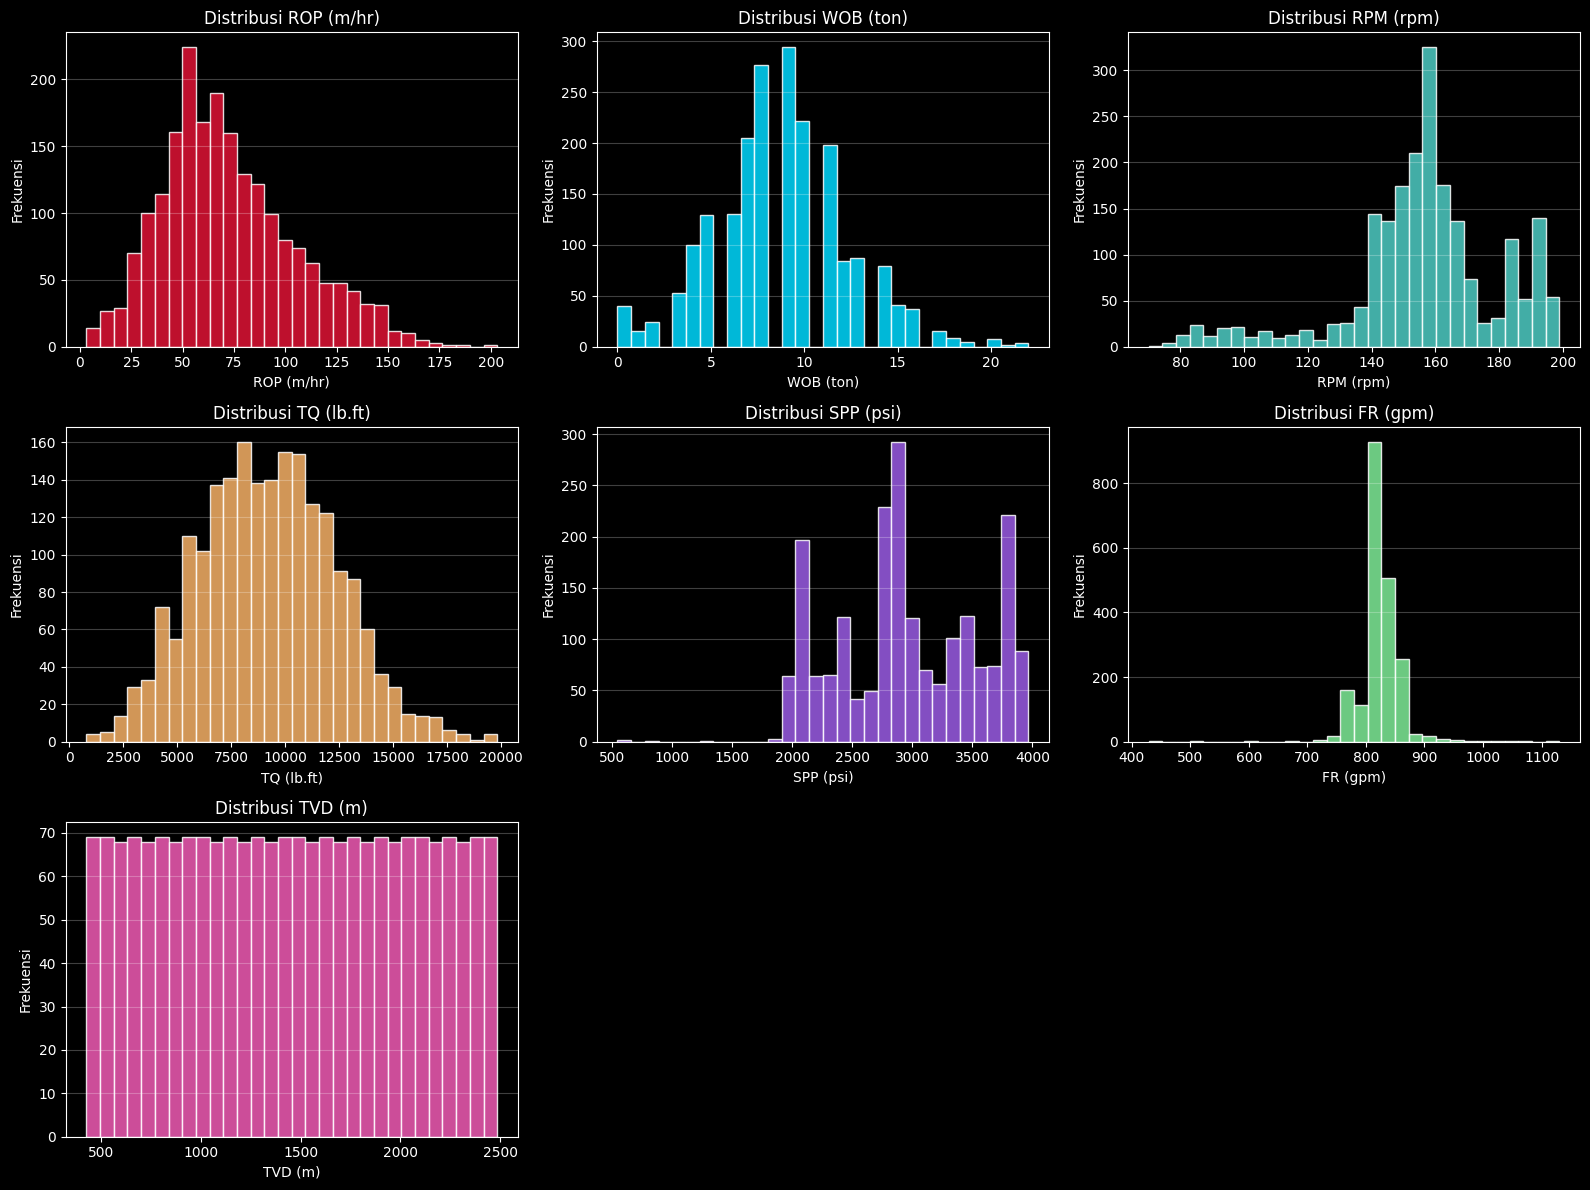

In [ ]:
# Histogram distribusi parameter drilling
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

params = ['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)',
          'TQ (lb.ft)', 'SPP (psi)', 'FR (gpm)']

colors = ['#e94560', '#4361ee', '#2a9d8f',
          '#f4a261', '#9b5de5', '#00b4d8']

for ax, param, color in zip(axes.flatten(), params, colors):
    ax.hist(df[param].dropna(), bins=30, color=color, edgecolor='white', alpha=0.85)
    ax.set_title(f'Distribusi {param}')
    ax.set_xlabel(param)
    ax.set_ylabel('Frekuensi')
    ax.grid(axis='y', alpha=0.25)

for ax in axes.flatten()[len(params):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

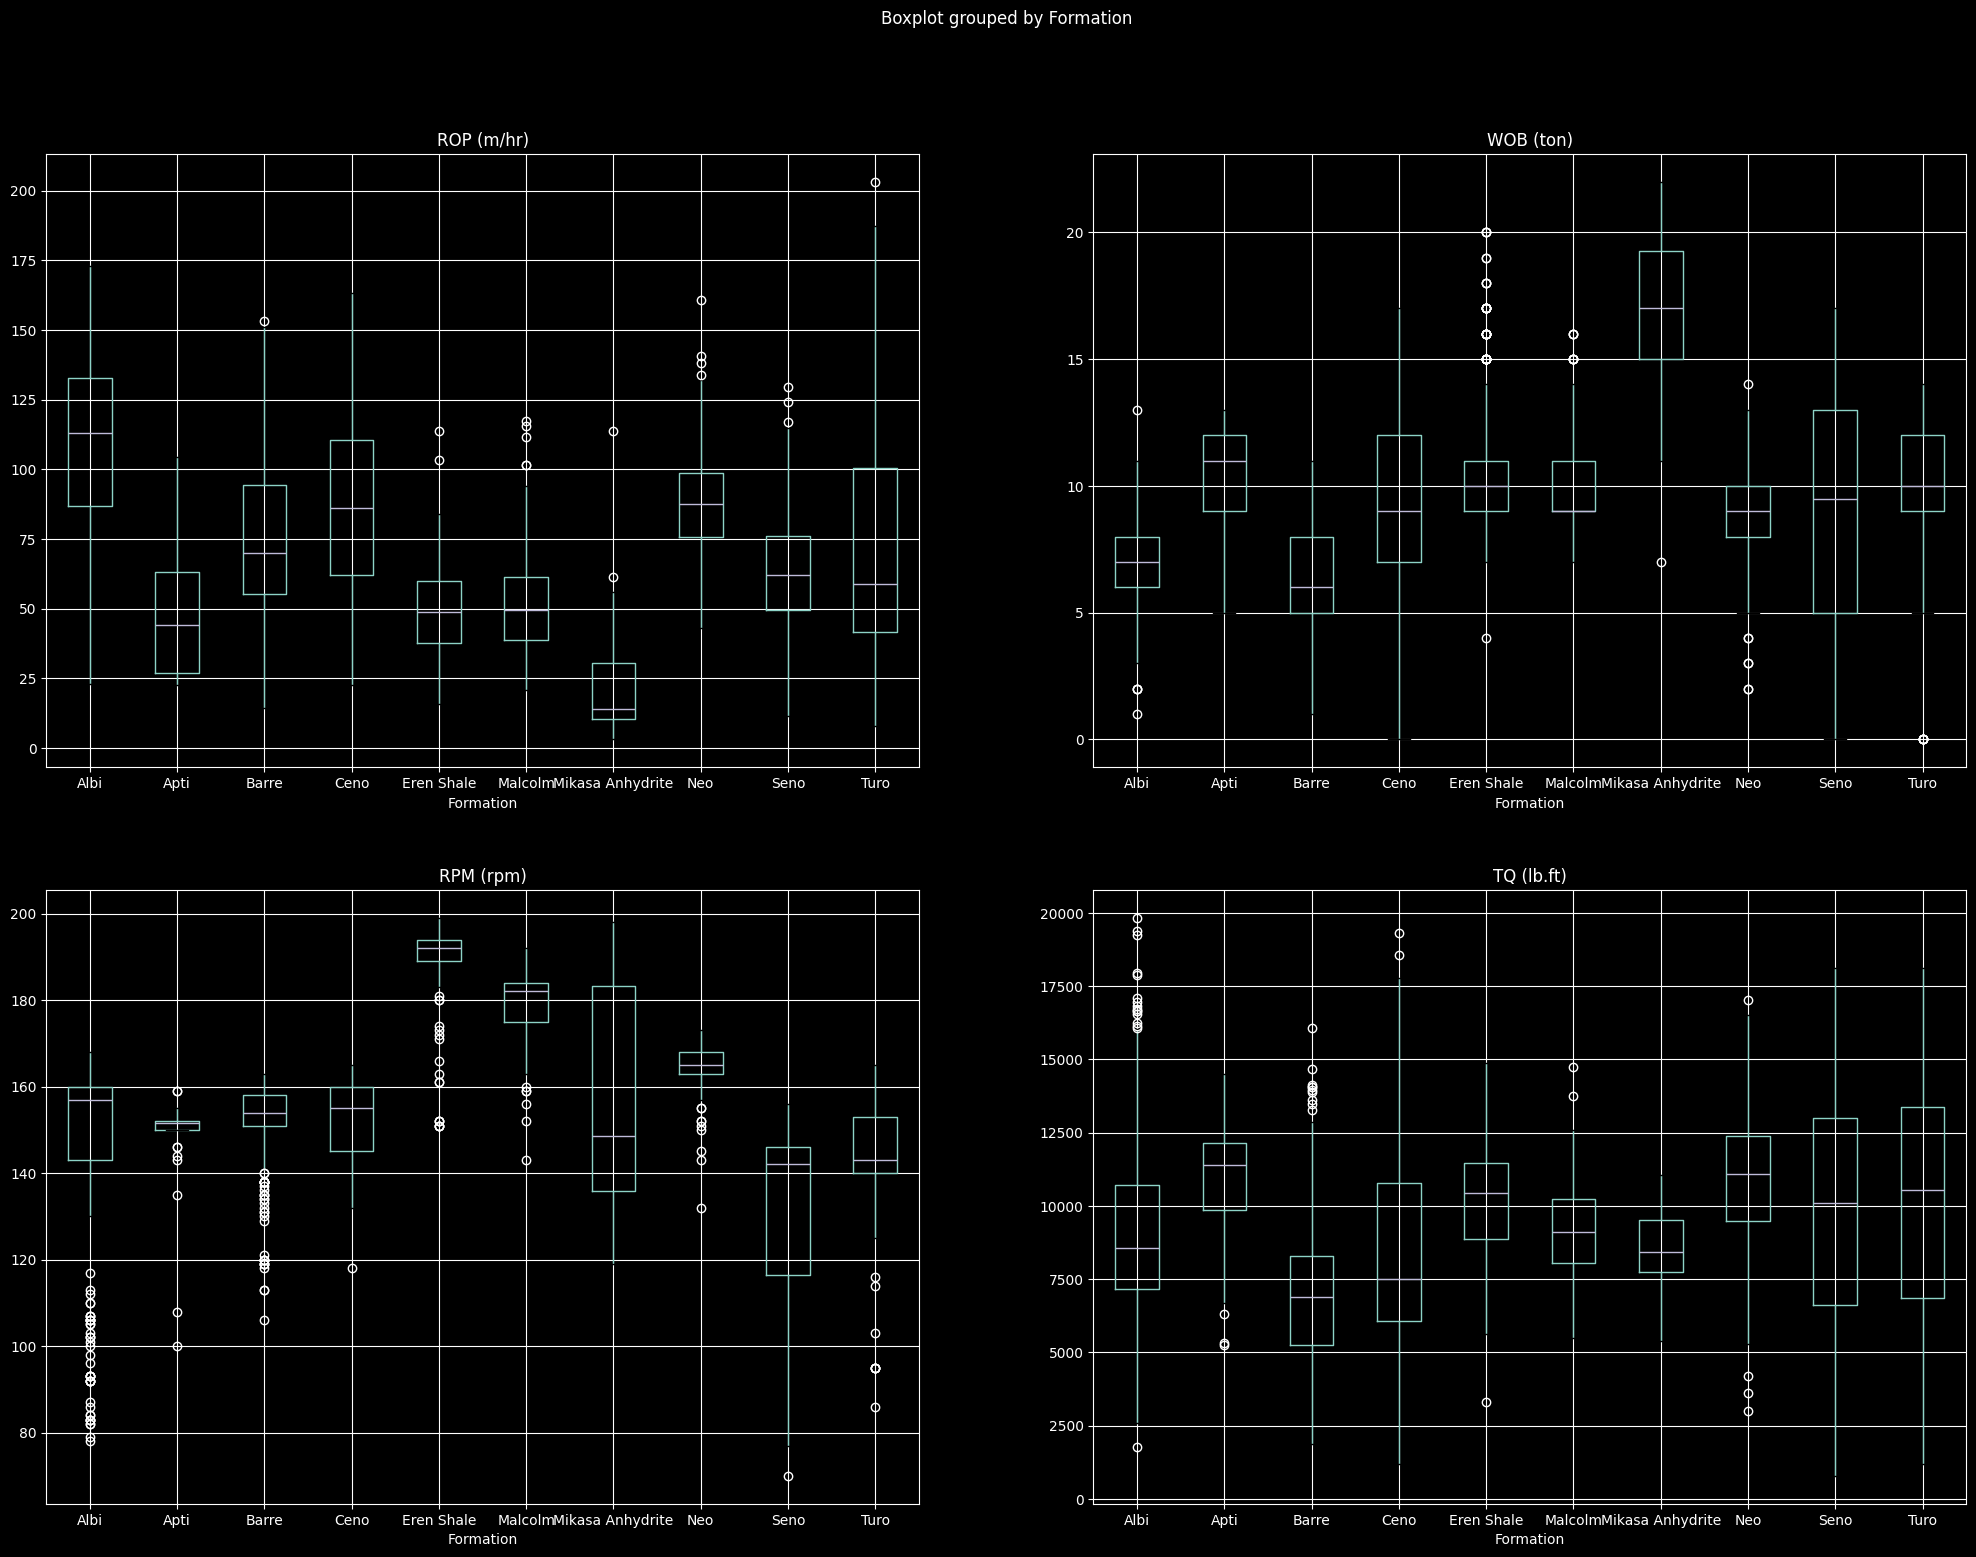

In [22]:
# Boxplot per formasi
fig, axes = plt.subplots(2, 2, figsize=(24, 18))
for ax, param in zip(axes.flatten(), ['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)']):
    df.boxplot(column=param, by='Formation', ax=ax)
plt.show()

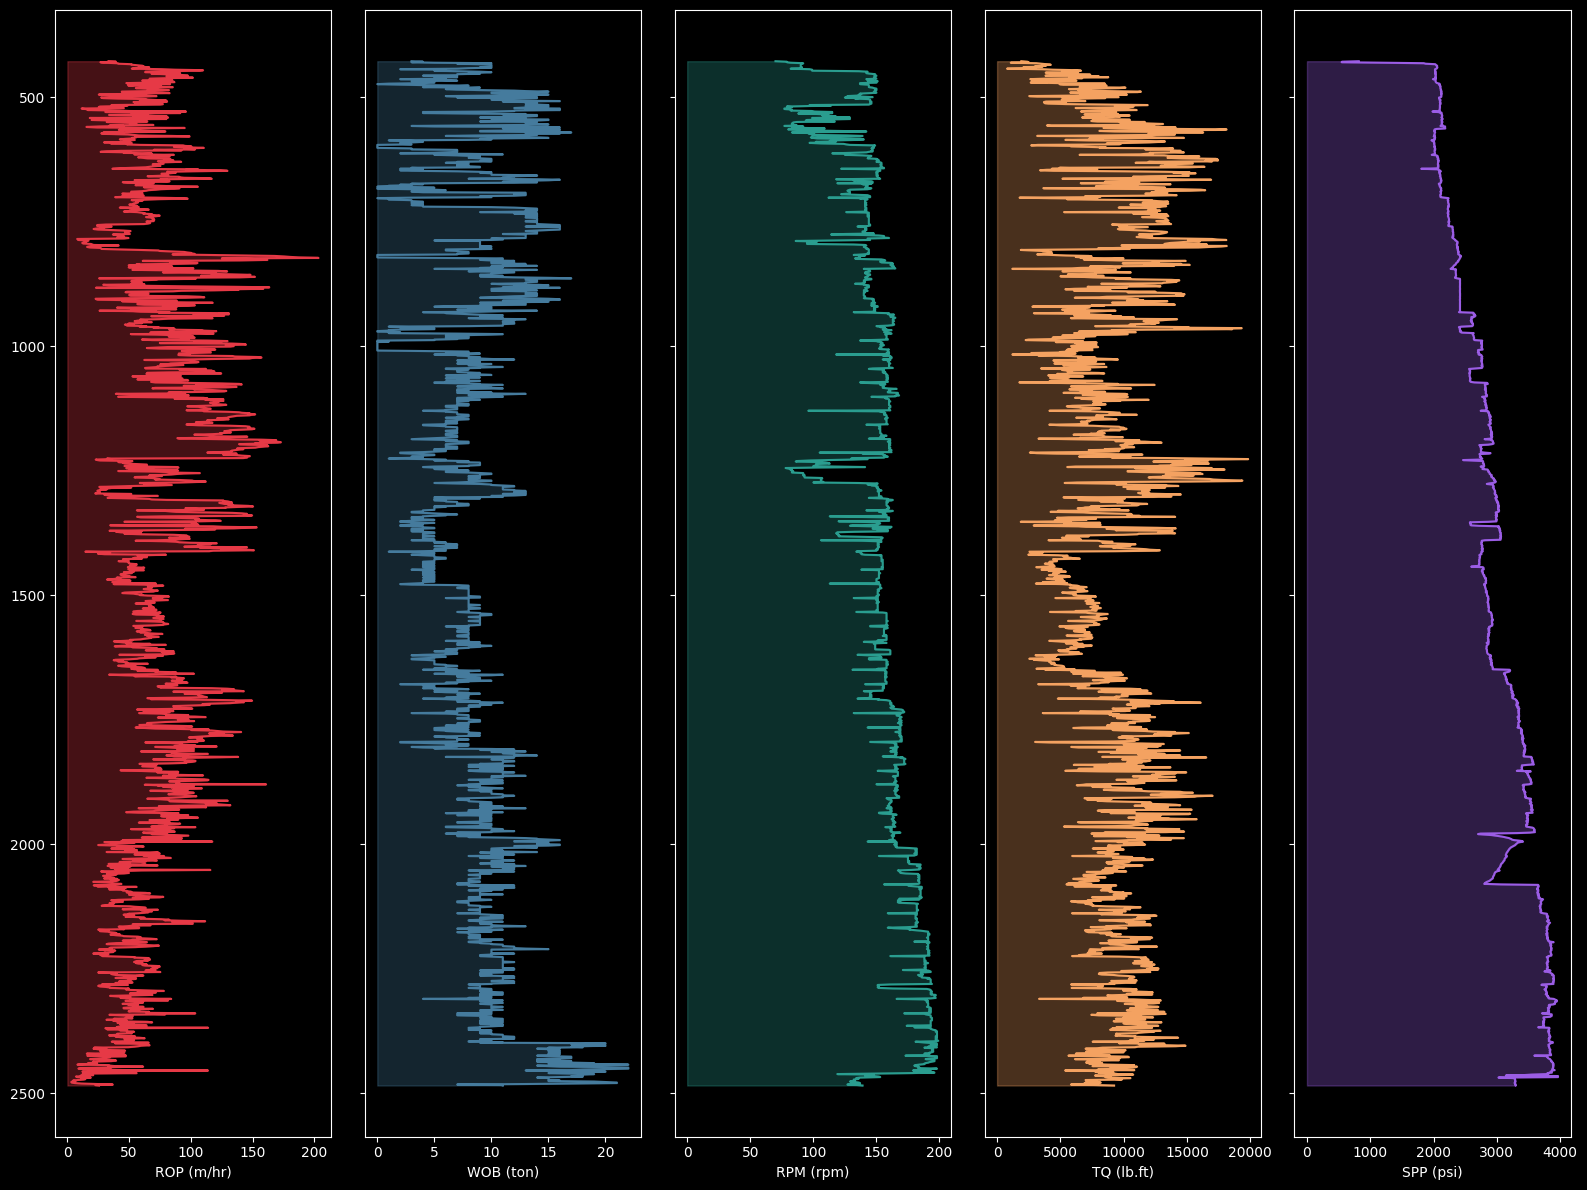

In [29]:
# Well Log Style Plot - Parameter vs Kedalaman
fig, axes = plt.subplots(1, 5, figsize=(16, 12), sharey=True)

params = ['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)', 'SPP (psi)']
colors = ['#e63946', '#457b9d', '#2a9d8f', '#f4a261', '#9b5de5']

for ax, param, color in zip(axes, params, colors):
    ax.plot(df[param], df['TVD (m)'], color=color)
    ax.fill_betweenx(df['TVD (m)'], 0, df[param], color=color, alpha=0.3)
    ax.set_xlabel(param)

axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

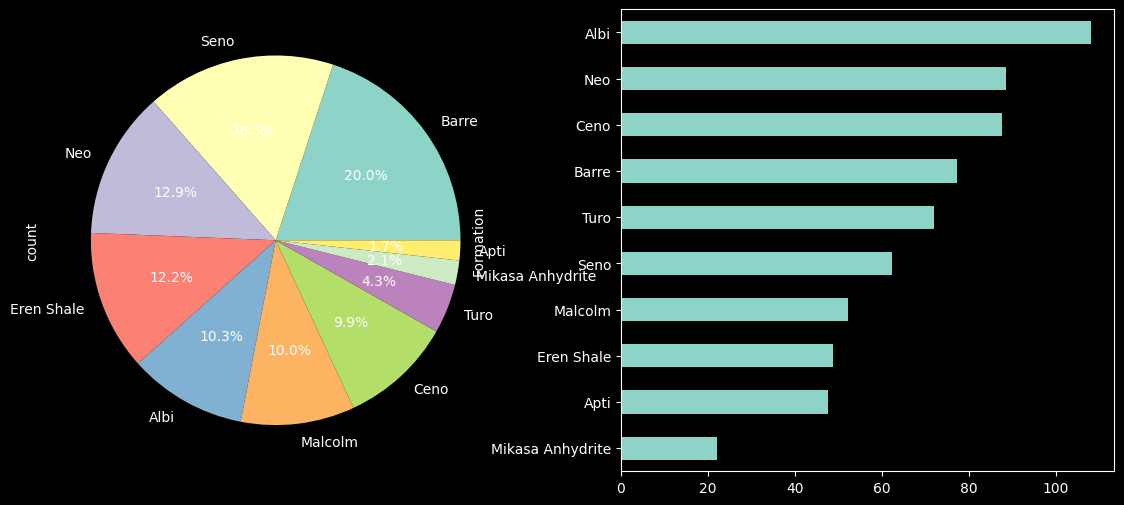

In [15]:
# Distribusi dan rata-rata ROP per formasi
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
df['Formation'].value_counts().plot.pie(ax=axes[0], autopct='%1.1f%%')
df.groupby('Formation')['ROP (m/hr)'].mean().sort_values().plot.barh(ax=axes[1])
plt.show()

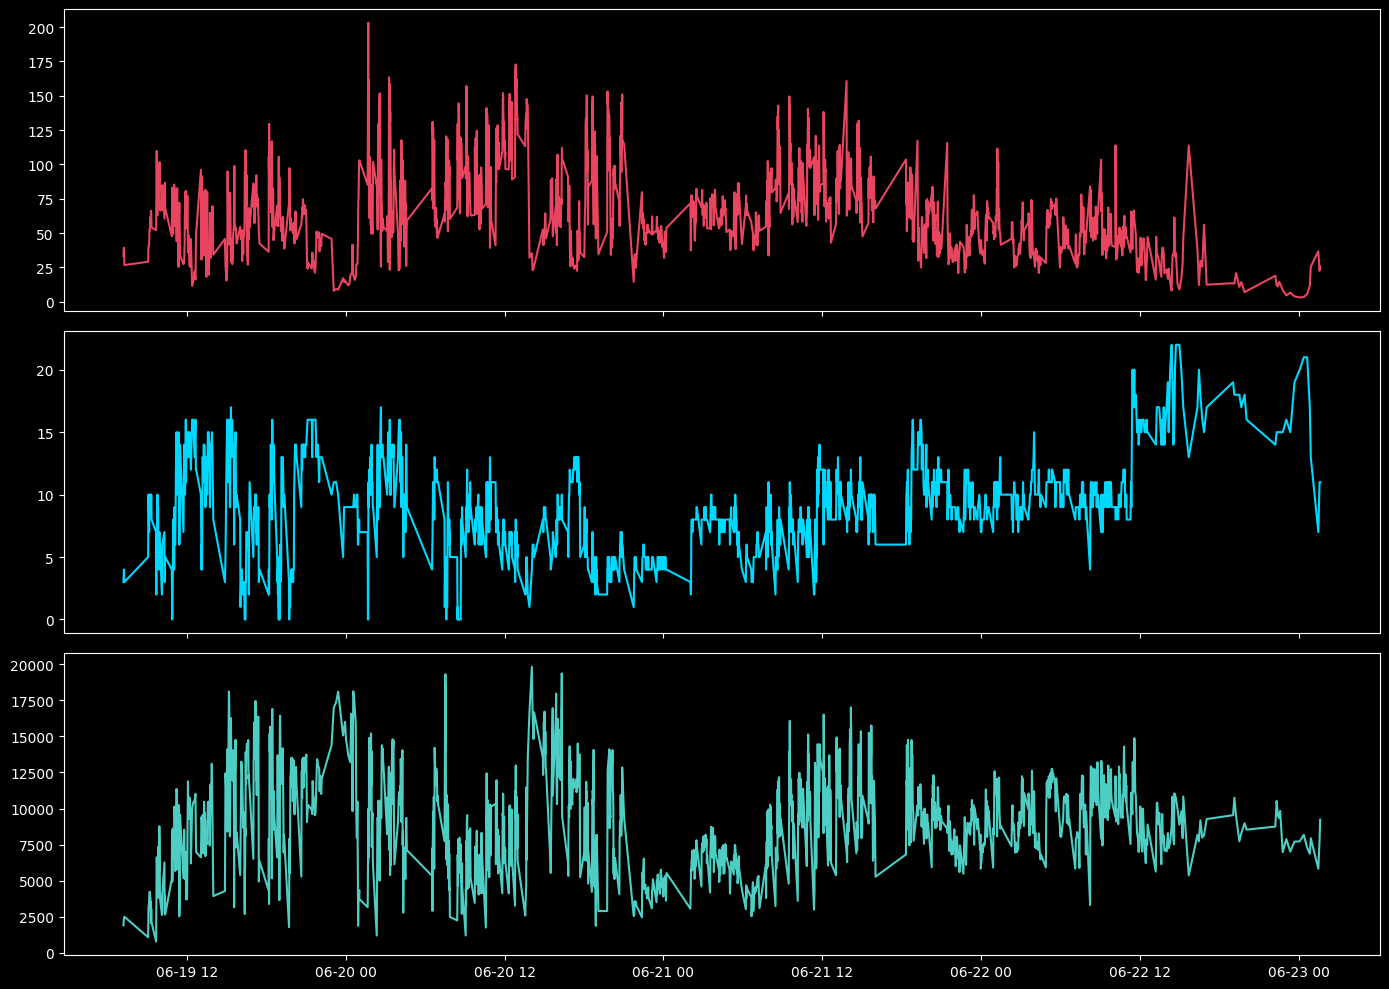

In [16]:
# Time series plot
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].plot(df['DATE TIME'], df['ROP (m/hr)'], color='#e94560')
axes[1].plot(df['DATE TIME'], df['WOB (ton)'], color='#00d9ff')
axes[2].plot(df['DATE TIME'], df['TQ (lb.ft)'], color='#4ecdc4')
plt.tight_layout(); plt.show()

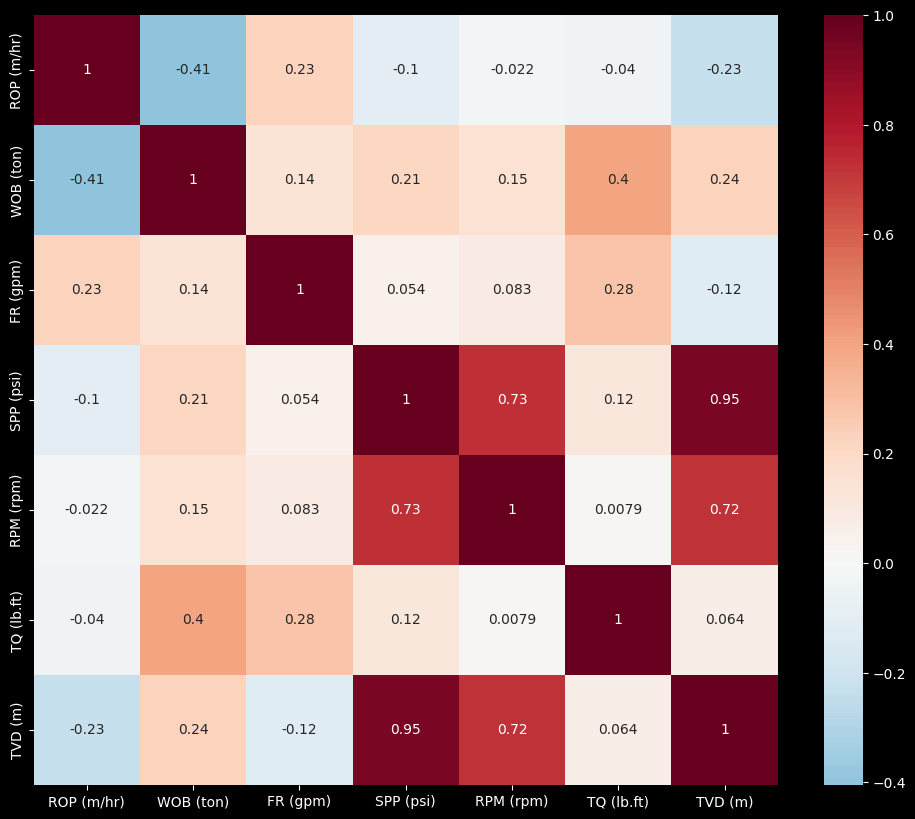

In [17]:
# Correlation heatmap
cols = ['ROP (m/hr)', 'WOB (ton)', 'FR (gpm)', 'SPP (psi)', 'RPM (rpm)', 'TQ (lb.ft)', 'TVD (m)']
corr = df[cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0)
plt.show()

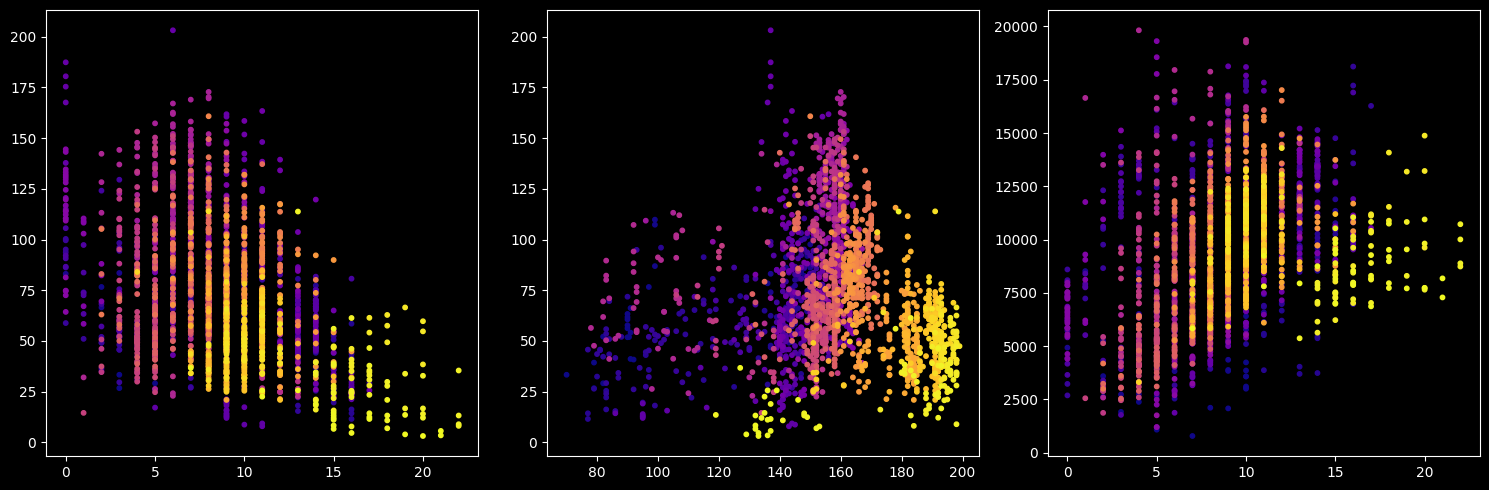

In [18]:
# Scatter plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].scatter(df['WOB (ton)'], df['ROP (m/hr)'], c=df['TVD (m)'], cmap='plasma', s=10)
axes[1].scatter(df['RPM (rpm)'], df['ROP (m/hr)'], c=df['TVD (m)'], cmap='plasma', s=10)
axes[2].scatter(df['WOB (ton)'], df['TQ (lb.ft)'], c=df['TVD (m)'], cmap='plasma', s=10)
plt.tight_layout(); plt.show()

In [32]:
# Simpan dataset yang sudah dibersihkan
df.to_csv('Well_Dataset_Clean.csv', index=False)
print("✅ Dataset disimpan: Well_Dataset_Clean.csv")
print(f"   Baris: {len(df):,} | Kolom: {len(df.columns)}")

✅ Dataset disimpan: Well_Dataset_Clean.csv
   Baris: 2,058 | Kolom: 17


In [ ]:
# 1. Cek persentase missing value awal
# 1. Cek persentase missing value awal
missing_pct = df['ROP (m/hr)'].isnull().mean() * 100
print(f"Persentase missing value ROP awal: {missing_pct:.2f}%")

# 2. Imputasi berdasarkan median masing-masing formasi
df['ROP (m/hr)'] = df.groupby('Formation')['ROP (m/hr)'].transform(
    lambda x: x.fillna(x.median())
)

# 3. Cek kembali missing value
print(
    "Jumlah missing value ROP setelah imputasi:",
    df['ROP (m/hr)'].isnull().sum()
)
print(f"Persentase missing value ROP awal: {missing_pct:.2f}%")

# 2. Imputasi nilai kosong pada ROP dengan Median dari masing-masing formasi
# Imputasi ROP dengan median setiap formasi
                # Cek persentase missing value awal
                # Cek persentase missing value awal
                # Cek persentase missing value awal
                missing_pct = df['ROP (m/hr)'].isnull().mean() * 100
                print(f"Persentase missing value ROP awal: {missing_pct:.2f}%")

                # Imputasi median berdasarkan formasi
                global_median = df['ROP (m/hr)'].median()

                df['ROP (m/hr)'] = (
                    df.groupby('Formation')['ROP (m/hr)']
                    .transform(lambda x: x.fillna(x.median()))
                    .fillna(global_median)
                )

                print(
                    "Jumlah missing value ROP setelah imputasi:",
                    df['ROP (m/hr)'].isnull().sum()
                )

                params = [
                    'ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)',
                    'TQ (lb.ft)', 'SPP (psi)', 'FR (gpm)', 'TVD (m)'
                ]

                colors = [
                    '#e11336', '#00d9ff', '#4ecdc4',
                    '#f7b267', '#9b5de5', '#80ed99', '#f15bb5'
                ]

                fig, axes = plt.subplots(3, 3, figsize=(16, 12))

                for ax, param, color in zip(axes.flatten(), params, colors):
                    ax.hist(
                        df[param].dropna(),
                        bins=30,
                        color=color,
                        edgecolor='white',
                        alpha=0.85
                    )
                    ax.set_title(f'Distribusi {param}')
                    ax.set_xlabel(param)
                    ax.set_ylabel('Frekuensi')
                    ax.grid(axis='y', alpha=0.25)

                for ax in axes.flatten()[len(params):]:
                    ax.set_visible(False)

                plt.tight_layout()
                plt.show()
                print(f"Persentase missing value ROP awal: {missing_pct:.2f}%")

                # Imputasi median berdasarkan formasi
                global_median = df['ROP (m/hr)'].median()

                df['ROP (m/hr)'] = (
                    df.groupby('Formation')['ROP (m/hr)']
                      .transform(lambda x: x.fillna(x.median()))
                      .fillna(global_median)
                )

                print(
                    "Jumlah missing value ROP setelah imputasi:",
                    df['ROP (m/hr)'].isnull().sum()
                )

                params = [
                    'ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)',
                    'TQ (lb.ft)', 'SPP (psi)', 'FR (gpm)', 'TVD (m)'
                ]

                colors = [
                    '#e11336', '#00d9ff', '#4ecdc4',
                    '#f7b267', '#9b5de5', '#80ed99', '#f15bb5'
                ]

                fig, axes = plt.subplots(3, 3, figsize=(16, 12))

                for ax, param, color in zip(axes.flatten(), params, colors):
                    ax.hist(
                        df[param].dropna(),
                        bins=30,
                        color=color,
                        edgecolor='white',
                        alpha=0.85
                    )
                    ax.set_title(f'Distribusi {param}')
                    ax.set_xlabel(param)
                    ax.set_ylabel('Frekuensi')
                    ax.grid(axis='y', alpha=0.25)

                for ax in axes.flatten()[len(params):]:
                    ax.set_visible(False)

                plt.tight_layout()
                plt.show()
                print(f"Persentase missing value ROP awal: {missing_pct:.2f}%")

                # Imputasi median berdasarkan formasi
                global_median = df['ROP (m/hr)'].median()

                df['ROP (m/hr)'] = (
                    df.groupby('Formation')['ROP (m/hr)']
                      .transform(lambda x: x.fillna(x.median()))
                      .fillna(global_median)
                )

                print(
                    "Jumlah missing value ROP setelah imputasi:",
                    df['ROP (m/hr)'].isnull().sum()
                )

                params = [
                    'ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)',
                    'TQ (lb.ft)', 'SPP (psi)', 'FR (gpm)', 'TVD (m)'
                ]

                colors = [
                    '#e11336', '#00d9ff', '#4ecdc4',
                    '#f7b267', '#9b5de5', '#80ed99', '#f15bb5'
                ]

                fig, axes = plt.subplots(3, 3, figsize=(16, 12))

                for ax, param, color in zip(axes.flatten(), params, colors):
                    ax.hist(
                        df[param].dropna(),
                        bins=30,
                        color=color,
                        edgecolor='white',
                        alpha=0.85
                    )
                    ax.set_title(f'Distribusi {param}')
                    ax.set_xlabel(param)
                    ax.set_ylabel('Frekuensi')
                    ax.grid(axis='y', alpha=0.25)

                for ax in axes.flatten()[len(params):]:
                    ax.set_visible(False)

                plt.tight_layout()
                plt.show()
                "colors = ['#e11336', '#00d9ff', '#4ecdc4', '#f7b267', '#9b5de5', '#80ed99', '#f15bb5']",
                "fig, axes = plt.subplots(3, 3, figsize=(16, 12))",
                "",
                "for ax, param, color in zip(axes.flatten(), params, colors):",
                "    ax.hist(df[param].dropna(), bins=30, color=color, edgecolor='white', alpha=0.85)",
                "    ax.set_title(f'Distribusi {param}')",
                "    ax.set_xlabel(param)",
                "    ax.set_ylabel('Frekuensi')",
                "    ax.grid(axis='y', alpha=0.25)",
                "",
                "for ax in axes.flatten()[len(params):]:",
                "    ax.set_visible(False)",
                "",
# Cek persentase missing value awal
missing_pct = df['ROP (m/hr)'].isnull().mean() * 100
print(f"Persentase missing value ROP awal: {missing_pct:.2f}%")

# Imputasi median berdasarkan formasi
global_median = df['ROP (m/hr)'].median()
df['ROP (m/hr)'] = df.groupby('Formation')['ROP (m/hr)'].transform(
    lambda x: x.fillna(x.median())
).fillna(global_median)

print(
    "Jumlah missing value ROP setelah imputasi:",
    df['ROP (m/hr)'].isnull().sum()
)

params = [
    'ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)',
    'TQ (lb.ft)', 'SPP (psi)', 'FR (gpm)', 'TVD (m)'
]

colors = [
    '#e11336', '#00d9ff', '#4ecdc4',
    '#f7b267', '#9b5de5', '#80ed99', '#f15bb5'
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, param, color in zip(axes.flatten(), params, colors):
    ax.hist(
        df[param].dropna(),
        bins=30,
        color=color,
        edgecolor='white',
        alpha=0.85
    )
    ax.set_title(f'Distribusi {param}')
    ax.set_xlabel(param)
    ax.set_ylabel('Frekuensi')
    ax.grid(axis='y', alpha=0.25)

for ax in axes.flatten()[len(params):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

IndentationError: unexpected indent (2714195105.py, line 22)